# Proiect Python – Analiza comenzilor GustoExpress Kovács Zsolt

## Partea 1 – Pregătirea datelor

#### 1.1. Încărcare și inspecție

În această etapă, încărcăm fișierele CSV folosind biblioteca Pandas și analizăm structura setului de date pentru a identifica informațiile disponibile și eventualele probleme.

In [1]:
import pandas as pd

comenzi = pd.read_csv("comenzi.csv")
restaurante = pd.read_csv("restaurante.csv")

In [2]:
comenzi.head()

,id_comanda,data_comanda,oras,id_restaurant,produse,nr_produse,valoare_produse,cost_livrare,timp_livrare_min,metoda_plata,rating_client,client_nou
0,100001,1/1/2025 15:25,București,18,['Shaorma medie'],1,24,9.99,30.0,Card,5.0,True
1,100002,1/1/2025 19:41,Brașov,18,"['Shaorma mare', 'Falafel wrap', 'Cartofi prăj...",4,73,12.99,22.0,Card,NaN,False
2,100003,1/1/2025 20:19,București,7,"['Pad Thai', 'Supă Miso', 'Noodles cu pui']",3,92,7.99,47.0,Cash,NaN,False
3,100004,1/2/2025 10:25,București,18,"['Shaorma medie', 'Shaorma mare', 'Falafel wrap']",3,78,9.99,29.0,Card,4.0,True
4,100005,1/2/2025 13:56,Timișoara,18,"['Shaorma medie', 'Shaorma mare', 'Ayran']",3,60,9.99,29.0,Card,5.0,False


In [3]:
comenzi.shape

(1950, 12)

In [4]:
comenzi.info()

<class 'pandas.DataFrame'>
RangeIndex: 1950 entries, 0 to 1949
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_comanda        1950 non-null   int64  
 1   data_comanda      1950 non-null   str    
 2   oras              1950 non-null   str    
 3   id_restaurant     1950 non-null   int64  
 4   produse           1950 non-null   str    
 5   nr_produse        1950 non-null   int64  
 6   valoare_produse   1950 non-null   int64  
 7   cost_livrare      1950 non-null   float64
 8   timp_livrare_min  1915 non-null   float64
 9   metoda_plata      1950 non-null   str    
 10  rating_client     1289 non-null   float64
 11  client_nou        1950 non-null   bool   
dtypes: bool(1), float64(3), int64(4), str(4)
memory usage: 169.6 KB


In [5]:
comenzi.describe()

,id_comanda,id_restaurant,nr_produse,valoare_produse,cost_livrare,timp_livrare_min,rating_client
count,1950.000000,1950.000000,1950.000000,1950.000000,1950.000000,1915.000000,1289.000000
mean,100975.500000,8.855385,2.216923,59.231282,8.659359,31.518538,4.267649
std,563.060832,5.554027,0.933181,31.739388,3.576571,9.332925,0.670277
min,100001.000000,1.000000,1.000000,0.000000,0.000000,12.000000,2.000000
25%,100488.250000,4.000000,2.000000,36.000000,7.990000,25.000000,4.000000
50%,100975.500000,8.000000,2.000000,56.500000,9.990000,31.000000,4.000000
75%,101462.750000,14.000000,3.000000,80.000000,9.990000,38.000000,5.000000
max,101950.000000,18.000000,4.000000,157.000000,12.990000,64.000000,5.000000


#### 1.2. Duplicate

In [6]:
duplicate_count = comenzi.duplicated().sum()

print("Numărul de rânduri duplicate:", duplicate_count)

Numărul de rânduri duplicate: 0


#### 1.3. Text standardizat

In [7]:
print(comenzi["oras"].value_counts(dropna=False))
print(comenzi["metoda_plata"].value_counts(dropna=False))

oras
București      818
Cluj-Napoca    356
Timișoara      284
Iași           274
Brașov         218
Name: count, dtype: int64
metoda_plata
Card    1388
Cash     562
Name: count, dtype: int64


#### 1.4. Valori lipsă 

În urma verificării setului de date, am identificat 35 de valori lipsă în coloana `timp_livrare_min` și 661 de valori lipsă în coloana `rating_client`.

Pentru `timp_livrare_min`, am completat valorile lipsă folosind mediana calculată separat pentru fiecare oraș.

Pentru `rating_client`, am decis să păstrez valorile lipsă, deoarece acestea reprezintă evaluări care nu au fost furnizate de clienți. Completarea lor cu valori statistice ar putea introduce informații artificiale și ar putea influența analiza satisfacției clienților.

In [10]:
comenzi.isnull().sum()

id_comanda            0
data_comanda          0
oras                  0
id_restaurant         0
produse               0
nr_produse            0
valoare_produse       0
cost_livrare          0
timp_livrare_min      0
metoda_plata          0
rating_client       661
client_nou            0
dtype: int64

In [9]:
comenzi["timp_livrare_min"] = comenzi.groupby("oras")["timp_livrare_min"].transform(
    lambda x: x.fillna(x.median())
)

#### 1.5. Valori invalide

Am identificat comenzile pentru care `valoare_produse` este mai mică sau egală cu 0 și le-am eliminat din setul de date.

Am păstrat doar comenzile cu o valoare pozitivă a produselor, pentru a evita includerea unor înregistrări invalide în analiza ulterioară.


In [11]:
invalid_count = (comenzi["valoare_produse"] <= 0).sum()

print("Numărul comenzilor invalide:", invalid_count)

Numărul comenzilor invalide: 3


In [12]:
comenzi = comenzi[comenzi["valoare_produse"] > 0].copy()

In [13]:
print("Numărul comenzilor invalide după eliminare:",
      (comenzi["valoare_produse"] <= 0).sum())

print("Numărul comenzilor rămase:", len(comenzi))

Numărul comenzilor invalide după eliminare: 0
Numărul comenzilor rămase: 1947


#### 1.6. Coloane noi

Am convertit coloana `data_comanda` la tipul datetime folosind funcția `pd.to_datetime()`.

Pe baza acesteia, am creat următoarele coloane:

* `luna` – luna în care a fost plasată comanda;
* `zi_saptamana` – ziua săptămânii, reprezentată numeric (0 = luni, 6 = duminică);
* `ora` – ora la care a fost plasată comanda.

De asemenea, am calculat coloana `valoare_totala` prin adunarea valorii produselor și a costului de livrare.


In [14]:
comenzi["data_comanda"] = pd.to_datetime(comenzi["data_comanda"])

In [15]:
comenzi["luna"] = comenzi["data_comanda"].dt.month

comenzi["zi_saptamana"] = comenzi["data_comanda"].dt.dayofweek

comenzi["ora"] = comenzi["data_comanda"].dt.hour

comenzi["valoare_totala"] = comenzi["valoare_produse"] + comenzi["cost_livrare"]

In [16]:
comenzi[["data_comanda", "luna", "zi_saptamana", "ora",
         "valoare_produse", "cost_livrare", "valoare_totala"]].head()

,data_comanda,luna,zi_saptamana,ora,valoare_produse,cost_livrare,valoare_totala
0,2025-01-01 15:25:00,1,2,15,24,9.99,33.99
1,2025-01-01 19:41:00,1,2,19,73,12.99,85.99
2,2025-01-01 20:19:00,1,2,20,92,7.99,99.99
3,2025-01-02 10:25:00,1,3,10,78,9.99,87.99
4,2025-01-02 13:56:00,1,3,13,60,9.99,69.99


In [17]:
comenzi.dtypes

id_comanda                   int64
data_comanda        datetime64[us]
oras                           str
id_restaurant                int64
produse                        str
nr_produse                   int64
valoare_produse              int64
cost_livrare               float64
timp_livrare_min           float64
metoda_plata                   str
rating_client              float64
client_nou                    bool
luna                         int32
zi_saptamana                 int32
ora                          int32
valoare_totala             float64
dtype: object

#### 1.7. Unire

Am unit seturile de date `comenzi` și `restaurante` folosind funcția `merge()` și coloana comună `id_restaurant`.

Am utilizat metoda `left join` pentru a păstra toate comenzile și pentru a adăuga informații despre restaurante, precum numele și tipul de bucătărie.

Astfel, fiecare comandă poate fi analizată și în funcție de caracteristicile restaurantului.


In [18]:
comenzi = comenzi.merge(restaurante, on="id_restaurant", how="left")

## Partea 2 – Funcții Python

#### 2.1. categorie_comanda 

In [19]:
def categorie_comanda(valoare):
    if valoare < 50:
        return "Mică"
    elif 50 <= valoare <= 99.99:
        return "Medie"
    else:
        return "Mare"

comenzi["categorie_comanda"] = comenzi["valoare_totala"].apply(categorie_comanda)

In [20]:
comenzi["categorie_comanda"].value_counts()

categorie_comanda
Medie    997
Mică     627
Mare     323
Name: count, dtype: int64

#### 2.2. rezumat_oras

Am definit funcția `rezumat_oras(date, oras)`, care primește setul de date și numele unui oraș.

Funcția filtrează comenzile pentru orașul respectiv și returnează un dicționar care conține:

* numele orașului;
* numărul total de comenzi;
* valoarea medie a comenzii;
* timpul mediu de livrare.

Am utilizat o buclă `for` pentru a parcurge lista celor cinci orașe și un `f-string` pentru afișarea rezultatelor într-un format clar și ușor de citit.


In [21]:
def rezumat_oras(date,oras):
    date_oras = date[date["oras"] == oras]

    rezumat = {
        "oras" : oras,
        "numar_comenzi" : len(date_oras),
        "valoare_medie" : date_oras["valoare_totala"].mean(),
        "timp_mediu_livrare" : date_oras["timp_livrare_min"].mean(),
    }

    return rezumat

In [22]:
orase = ["București", "Cluj-Napoca", "Timișoara", "Iași", "Constanța"]

In [23]:
for oras in orase:
    rezumat = rezumat_oras(comenzi, oras)

    print(
        f"{rezumat['oras']}: {rezumat['numar_comenzi']} comenzi, "
        f"valoare medie {rezumat['valoare_medie']:.2f} lei, "
        f"livrare în medie {rezumat['timp_mediu_livrare']:.1f} min"
    )

București: 817 comenzi, valoare medie 68.13 lei, livrare în medie 36.9 min
Cluj-Napoca: 356 comenzi, valoare medie 68.62 lei, livrare în medie 27.0 min
Timișoara: 283 comenzi, valoare medie 68.16 lei, livrare în medie 28.5 min
Iași: 273 comenzi, valoare medie 66.91 lei, livrare în medie 27.9 min
Constanța: 0 comenzi, valoare medie nan lei, livrare în medie nan min


## Partea 3 – Întrebări de analiză

#### 3.1.

În urma analizei, am observat că cel mai comandat tip de bucătărie este **[categoria cea mai populară]**, cu **[număr] comenzi**, reprezentând **[procent]%** din total.

La polul opus, categoria cel mai puțin comandată este **[categoria cea mai puțin populară]**, cu **[număr] comenzi** (**[procent]%**).

Aceste rezultate evidențiază diferențele de popularitate dintre tipurile de bucătărie și pot ajuta la identificarea preferințelor clienților.

In [24]:
# Numărul comenzilor pentru fiecare tip de bucătărie
comenzi_bucatarie = comenzi["tip_bucatarie"].value_counts()

# Procentul comenzilor pentru fiecare tip de bucătărie
procent_bucatarie = comenzi["tip_bucatarie"].value_counts(normalize=True) * 100

# Crearea tabelului
tabel_bucatarie = pd.DataFrame({
    "Numar comenzi": comenzi_bucatarie,
    "Procent (%)": procent_bucatarie
})

# Ordonare descrescătoare
tabel_bucatarie = tabel_bucatarie.sort_values(
    by="Numar comenzi",
    ascending=False
)

tabel_bucatarie["Procent (%)"] = tabel_bucatarie["Procent (%)"].round(2)

tabel_bucatarie

,Numar comenzi,Procent (%)
tip_bucatarie,,
Pizza,455,23.37
Burgeri,356,18.28
Fast-food,295,15.15
Tradițional,285,14.64
Asiatic,270,13.87
Healthy,163,8.37
Desert,123,6.32


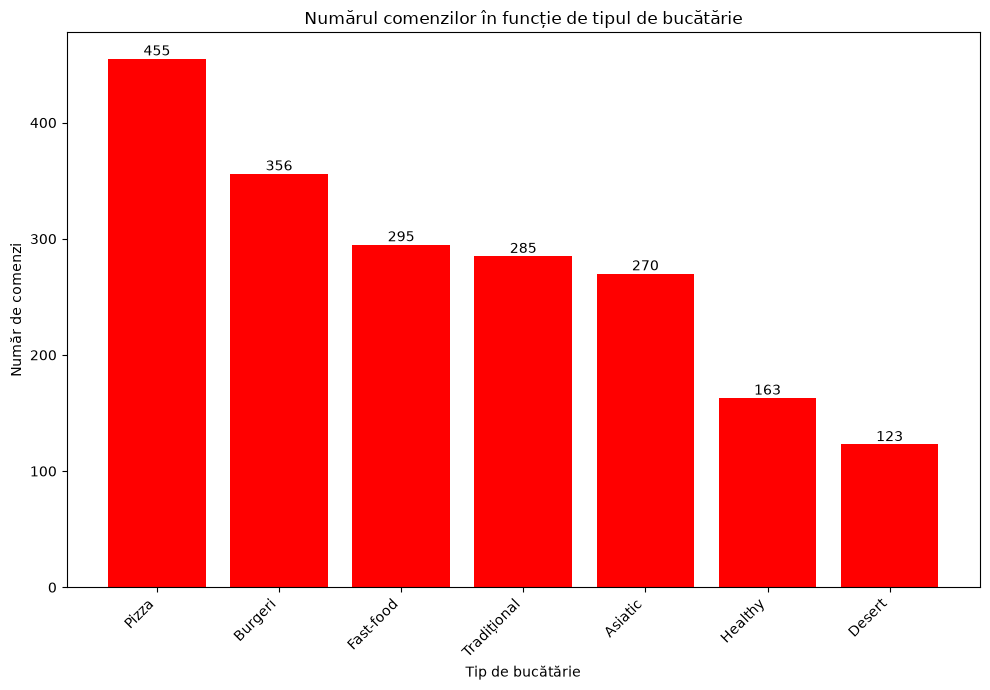

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

bars = plt.bar(
    tabel_bucatarie.index,
    tabel_bucatarie["Numar comenzi"],
    color="red"
)

# A valori afișate deasupra barelor
for bar in bars:
    valoare = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        valoare,
        int(valoare),
        ha="center",
        va="bottom"
    )

plt.title("Numărul comenzilor în funcție de tipul de bucătărie")
plt.xlabel("Tip de bucătărie")
plt.ylabel("Număr de comenzi")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 3.2. 

În urma analizei, am observat că orașul cu cele mai mari încasări este [ORAȘ], cu un total de [SUMĂ] lei.

Acesta are [NUMĂR] comenzi, iar valoarea medie a unei comenzi este de [MEDIE] lei.

Diferențele dintre încasările orașelor sunt influențate atât de numărul comenzilor, cât și de valoarea medie a acestora. În cazul orașului cu cele mai mari încasări, factorul principal este [numărul mai mare de comenzi / valoarea medie mai ridicată a comenzilor], conform rezultatelor obținute.

In [27]:
vanzari_oras = comenzi.groupby("oras").agg(
    numar_comenzi=("id_comanda", "count"),
    incasari_totale=("valoare_totala", "sum"),
    valoare_medie=("valoare_totala", "mean")
)

vanzari_oras = vanzari_oras.sort_values(
    by="incasari_totale",
    ascending=False
)

vanzari_oras["incasari_totale"] = vanzari_oras["incasari_totale"].round(2)
vanzari_oras["valoare_medie"] = vanzari_oras["valoare_medie"].round(2)

vanzari_oras

,numar_comenzi,incasari_totale,valoare_medie
oras,,,
București,817,55665.89,68.13
Cluj-Napoca,356,24427.84,68.62
Timișoara,283,19288.51,68.16
Iași,273,18266.52,66.91
Brașov,218,14707.02,67.46


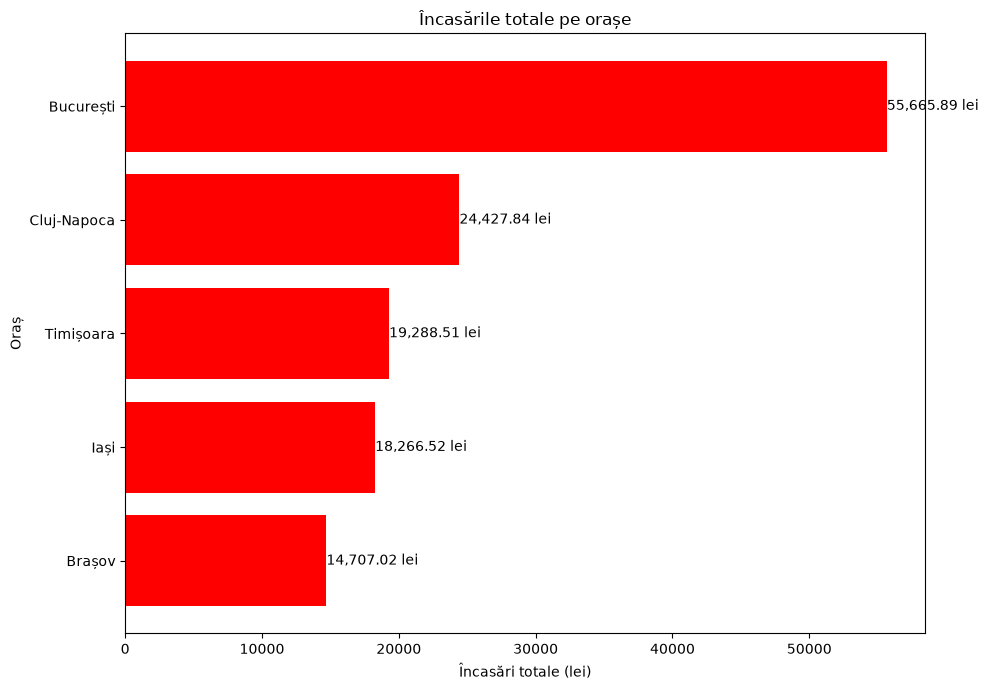

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

bars = plt.barh(
    vanzari_oras.index,
    vanzari_oras["incasari_totale"],
    color="red"
)

# Afișarea valorilor pe bare
for bar in bars:
    valoare = bar.get_width()

    plt.text(
        valoare,
        bar.get_y() + bar.get_height() / 2,
        f"{valoare:,.2f} lei",
        va="center",
        ha="left"
    )

plt.title("Încasările totale pe orașe")
plt.xlabel("Încasări totale (lei)")
plt.ylabel("Oraș")

# Orașul cu cele mai mici încasări apare jos
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [29]:
oras_top = vanzari_oras.index[0]

print("Orașul cu cele mai mari încasări:", oras_top)
print("Încasări totale:", vanzari_oras.iloc[0]["incasari_totale"], "lei")
print("Număr de comenzi:", vanzari_oras.iloc[0]["numar_comenzi"])
print("Valoare medie:", vanzari_oras.iloc[0]["valoare_medie"], "lei")

Orașul cu cele mai mari încasări: București
Încasări totale: 55665.89 lei
Număr de comenzi: 817.0
Valoare medie: 68.13 lei


#### 3.3. 

Analizând evoluția comenzilor pe luni, am observat că luna cu cele mai multe comenzi este [LUNA], cu [NUMĂR] comenzi, iar luna cu cele mai puține comenzi este [LUNA], cu [NUMĂR] comenzi.

Se observă [o creștere / o scădere / variații sezoniere] a numărului de comenzi în anumite perioade ale anului.

Aceste variații ar putea fi influențate de sezonalitate, sărbători, condițiile meteorologice sau promoțiile oferite de restaurante. Totuși, aceste cauze reprezintă ipoteze și ar necesita analize suplimentare pentru a fi confirmate

In [49]:
vanzari_lunare = comenzi.groupby("luna").agg(
    numar_comenzi=("id_comanda", "count"),
    incasari_totale=("valoare_totala", "sum")
)

# Asigurăm afișarea tuturor lunilor în ordine
vanzari_lunare = vanzari_lunare.reindex(range(1, 13), fill_value=0)

vanzari_lunare["incasari_totale"] = vanzari_lunare["incasari_totale"].round(2)

vanzari_lunare

,numar_comenzi,incasari_totale
luna,,
1,190,13150.34
2,193,12863.21
3,177,12686.55
4,146,10307.79
5,159,10228.52
6,128,8362.86
7,134,9294.85
8,126,9093.89
9,158,11254.65


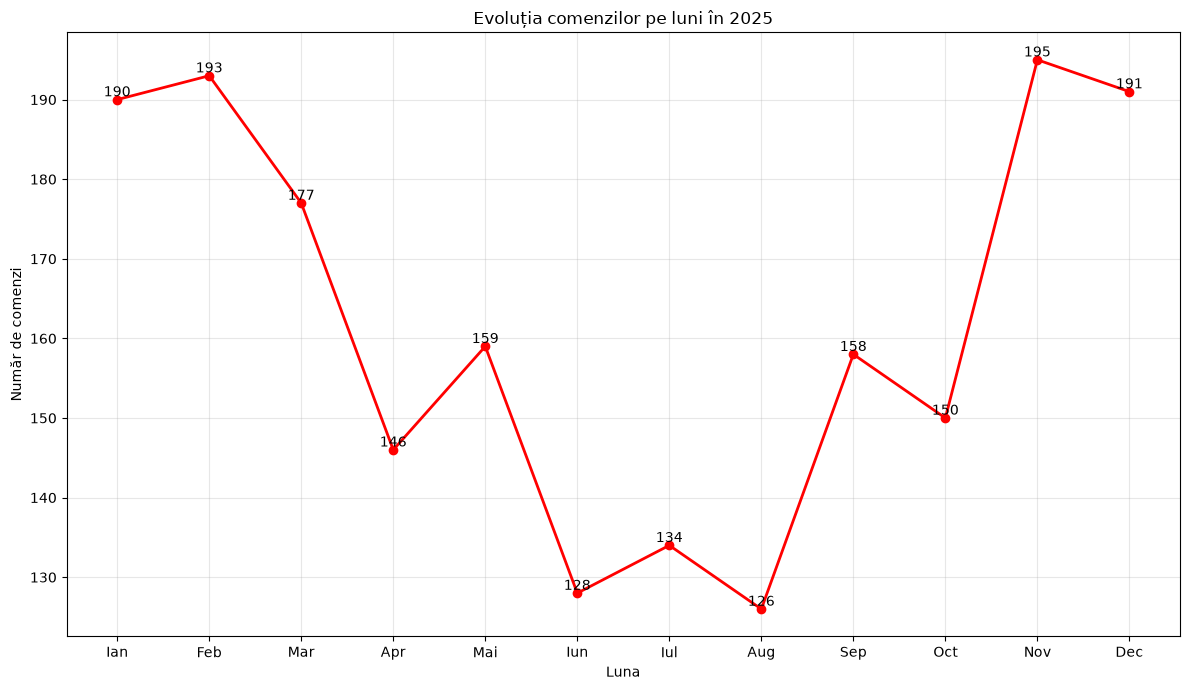

In [50]:
import matplotlib.pyplot as plt

luni = ["Ian", "Feb", "Mar", "Apr", "Mai", "Iun",
        "Iul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 7))

plt.plot(
    luni,
    vanzari_lunare["numar_comenzi"],
    marker="o",
    color="red",
    linewidth=2
)

# Afișarea valorilor pentru fiecare lună
for i, valoare in enumerate(vanzari_lunare["numar_comenzi"]):
    plt.text(i, valoare, str(valoare), ha="center", va="bottom")

plt.title("Evoluția comenzilor pe luni în 2025")
plt.xlabel("Luna")
plt.ylabel("Număr de comenzi")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
best_month = vanzari_lunare["numar_comenzi"].idxmax()
worst_month = vanzari_lunare["numar_comenzi"].idxmin()

print("Cea mai bună lună:", luni[best_month - 1])
print("Număr comenzi:", vanzari_lunare.loc[best_month, "numar_comenzi"])

print("\nCea mai slabă lună:", luni[worst_month - 1])
print("Număr comenzi:", vanzari_lunare.loc[worst_month, "numar_comenzi"])

Cea mai bună lună: Nov
Număr comenzi: 195

Cea mai slabă lună: Aug
Număr comenzi: 126


#### 3.4. 

Analiza comenzilor în funcție de oră și ziua săptămânii ne ajută să identificăm perioadele cu cea mai mare activitate.

Cele mai multe comenzi sunt înregistrate la ora [ora de vârf], iar ziua cu cel mai mare număr de comenzi este [ziua de vârf].

În aceste perioade, GustoExpress ar trebui să asigure un număr suficient de curieri și personal în restaurante, să optimizeze distribuirea comenzilor și să reducă timpul de livrare.

De asemenea, firma poate utiliza aceste informații pentru planificarea programului angajaților și pentru gestionarea mai eficientă a resurselor.

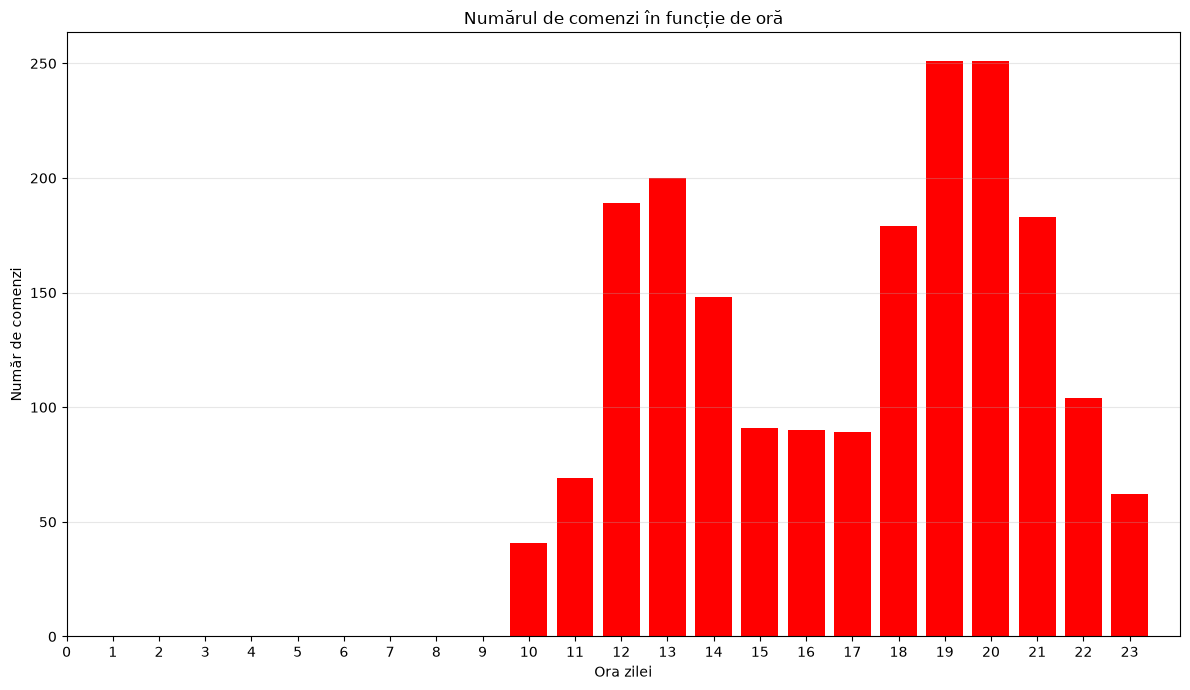

In [60]:
import matplotlib.pyplot as plt

comenzi_pe_ora = comenzi["ora"].value_counts().sort_index()

plt.figure(figsize=(12, 7))

plt.bar(comenzi_pe_ora.index, comenzi_pe_ora.values, color="red")

plt.title("Numărul de comenzi în funcție de oră")
plt.xlabel("Ora zilei")
plt.ylabel("Număr de comenzi")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

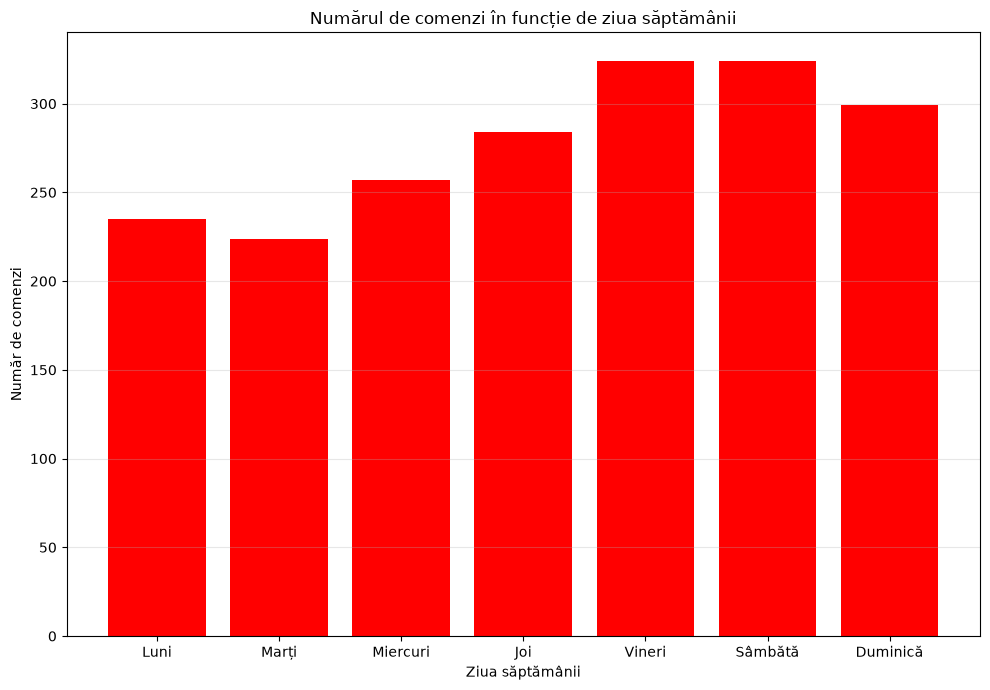

In [61]:
zile_romana = {
    0: "Luni",
    1: "Marți",
    2: "Miercuri",
    3: "Joi",
    4: "Vineri",
    5: "Sâmbătă",
    6: "Duminică"
}

comenzi["zi_nume"] = comenzi["zi_saptamana"].map(zile_romana)

comenzi_pe_zi = comenzi["zi_nume"].value_counts()

ordine_zile = ["Luni", "Marți", "Miercuri", "Joi",
               "Vineri", "Sâmbătă", "Duminică"]

comenzi_pe_zi = comenzi_pe_zi.reindex(ordine_zile, fill_value=0)

plt.figure(figsize=(10, 7))

plt.bar(comenzi_pe_zi.index, comenzi_pe_zi.values, color="red")

plt.title("Numărul de comenzi în funcție de ziua săptămânii")
plt.xlabel("Ziua săptămânii")
plt.ylabel("Număr de comenzi")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [62]:
ora_maxima = comenzi_pe_ora.idxmax()
numar_comenzi_ora = comenzi_pe_ora.max()

zi_maxima = comenzi_pe_zi.idxmax()
numar_comenzi_zi = comenzi_pe_zi.max()

print(f"Ora de vârf: {ora_maxima}:00")
print(f"Număr de comenzi: {numar_comenzi_ora}")

print(f"\nZiua cu cele mai multe comenzi: {zi_maxima}")
print(f"Număr de comenzi: {numar_comenzi_zi}")

Ora de vârf: 19:00
Număr de comenzi: 251

Ziua cu cele mai multe comenzi: Vineri
Număr de comenzi: 324


#### 3.5.

Analiza evidențiază relația dintre timpul de livrare și satisfacția clienților.

Categoria de livrare cu cel mai mare rating mediu este [categoria], cu un rating de [valoare], în timp ce categoria cu cel mai mic rating este [categoria], cu un rating de [valoare].

Coeficientul de corelație dintre timpul de livrare și rating este [valoare], ceea ce indică o relație [negativă/pozitivă/slabă] între cele două variabile.

Orașul [numele orașului] înregistrează cel mai mare timp mediu de livrare, de [valoare] minute, motiv pentru care ar trebui să fie o prioritate pentru îmbunătățirea procesului de livrare.

Compania ar putea optimiza distribuirea curierilor, îmbunătăți organizarea comenzilor și reduce timpul de așteptare pentru a crește satisfacția clienților.

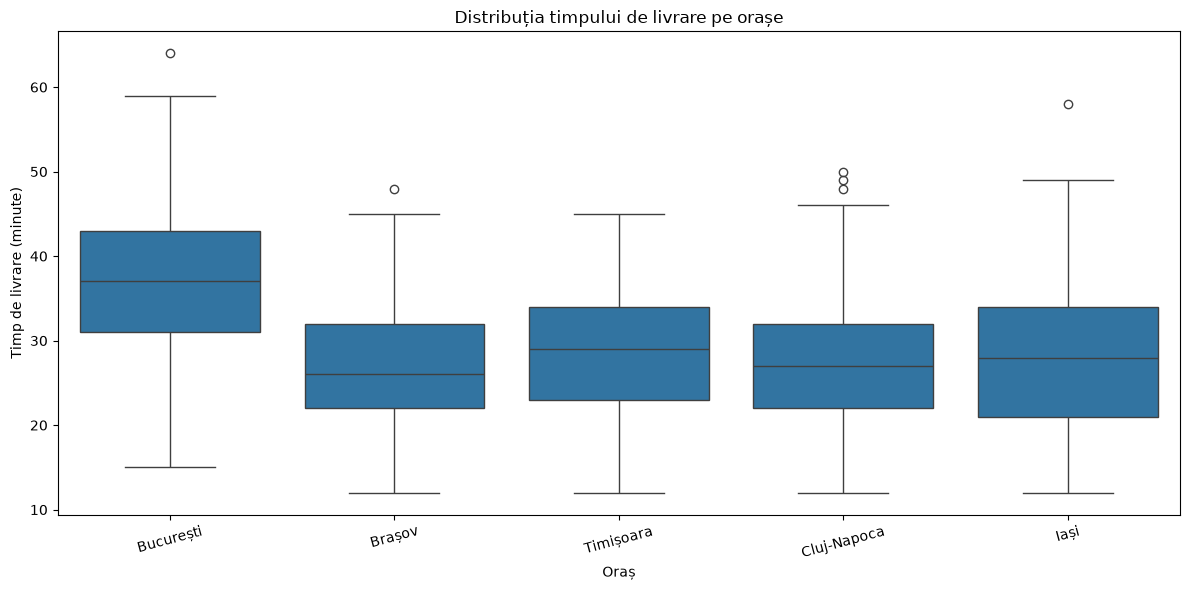

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.boxplot(data=comenzi, x="oras", y="timp_livrare_min")

plt.title("Distribuția timpului de livrare pe orașe")
plt.xlabel("Oraș")
plt.ylabel("Timp de livrare (minute)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [70]:
timp_mediu_oras = comenzi.groupby("oras")["timp_livrare_min"].mean()

timp_mediu_oras = timp_mediu_oras.sort_values(ascending=False).round(2)

timp_mediu_oras

oras
București      36.92
Timișoara      28.53
Iași           27.90
Brașov         27.13
Cluj-Napoca    26.97
Name: timp_livrare_min, dtype: float64

In [73]:
def categorie_livrare(minute):
    if minute <= 30:
        return "Rapidă (≤30 min)"
    elif minute <= 45:
        return "Normală (31–45 min)"
    else:
        return "Lentă (>45 min)"

comenzi["categorie_livrare"] = comenzi["timp_livrare_min"].apply(categorie_livrare)

comenzi[["timp_livrare_min", "categorie_livrare"]].head(10)

,timp_livrare_min,categorie_livrare
0,30.0,Rapidă (≤30 min)
1,22.0,Rapidă (≤30 min)
2,47.0,Lentă (>45 min)
3,29.0,Rapidă (≤30 min)
4,29.0,Rapidă (≤30 min)
5,42.0,Normală (31–45 min)
6,38.0,Normală (31–45 min)
7,26.0,Rapidă (≤30 min)
8,27.0,Rapidă (≤30 min)
9,38.0,Normală (31–45 min)


In [74]:
rating_categorii = comenzi.groupby("categorie_livrare")["rating_client"].mean()

ordine_categorii = [
    "Rapidă (≤30 min)",
    "Normală (31–45 min)",
    "Lentă (>45 min)"
]

rating_categorii = rating_categorii.reindex(ordine_categorii).round(2)

rating_categorii

categorie_livrare
Rapidă (≤30 min)       4.50
Normală (31–45 min)    4.12
Lentă (>45 min)        3.62
Name: rating_client, dtype: float64

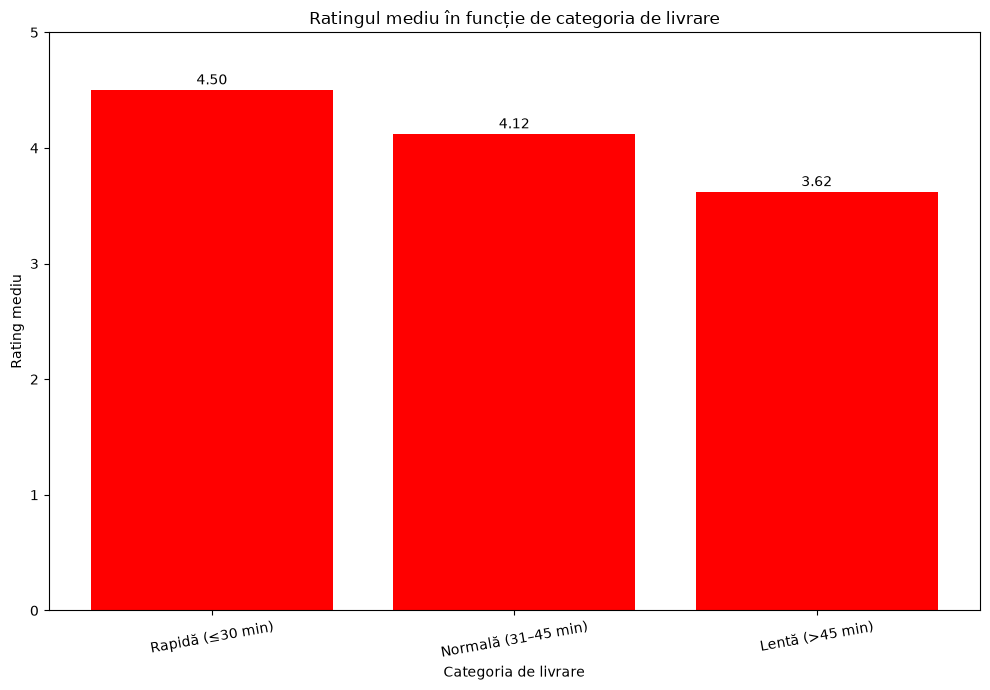

In [77]:
plt.figure(figsize=(10, 7))

plt.bar(rating_categorii.index, rating_categorii.values, color="red")

plt.title("Ratingul mediu în funcție de categoria de livrare")
plt.xlabel("Categoria de livrare")
plt.ylabel("Rating mediu")
plt.ylim(0, 5)

for i, valoare in enumerate(rating_categorii.values):
    if pd.notna(valoare):
        plt.text(i, valoare + 0.05, f"{valoare:.2f}", ha="center")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [78]:
corelatie = comenzi["timp_livrare_min"].corr(comenzi["rating_client"])

print(f"Corelația dintre timpul de livrare și rating: {corelatie:.3f}")

Corelația dintre timpul de livrare și rating: -0.360


In [79]:
analiza_orase = comenzi.groupby("oras").agg(
    timp_mediu=("timp_livrare_min", "mean"),
    rating_mediu=("rating_client", "mean"),
    numar_comenzi=("id_comanda", "count")
)

analiza_orase = analiza_orase.sort_values(
    by="timp_mediu",
    ascending=False
).round(2)

analiza_orase

,timp_mediu,rating_mediu,numar_comenzi
oras,,,
București,36.92,4.12,817
Timișoara,28.53,4.37,283
Iași,27.90,4.30,273
Brașov,27.13,4.40,218
Cluj-Napoca,26.97,4.40,356


## Partea 4 – Concluzii finale și export

#### 4.1

Concluzii principale și recomandări pentru management

Concluzii principale

1. **Preferințele culinare:** Categoria **Pizza** este cea mai populară, cu **455 de comenzi**, reprezentând **23,37%** din totalul comenzilor analizate. Acest rezultat indică o cerere ridicată pentru produsele din această categorie.

2. **Performanța pe orașe:** **București** este orașul cu cele mai multe comenzi și cele mai mari încasări, cu **817 comenzi** și **55.665,89 lei** încasări totale. Valoarea medie a unei comenzi este de **68,13 lei**, ceea ce evidențiază importanța acestei piețe pentru companie.

3. **Evoluția comenzilor pe luni:** Cea mai bună lună din 2025 a fost **noiembrie**, cu **195 de comenzi**, în timp ce cea mai slabă lună a fost **august**, cu **126 de comenzi**. Diferența de **69 de comenzi** arată că volumul comenzilor variază semnificativ pe parcursul anului.

4. **Perioadele de vârf:** Cea mai aglomerată oră este **19:00**, cu **251 de comenzi**, iar ziua cu cele mai multe comenzi este **vineri**, cu **324 de comenzi**. Aceste perioade reprezintă momente importante pentru planificarea resurselor și a personalului.

5. **Timpul de livrare și satisfacția clienților:** Bucureștiul are cel mai mare timp mediu de livrare, de **36,92 minute**, și cel mai mic rating mediu dintre orașele analizate, de **4,12**. În comparație, Cluj-Napoca are un timp mediu de livrare de **26,97 minute** și un rating mediu de **4,40**. Aceste rezultate sugerează că îmbunătățirea timpului de livrare în București ar putea contribui la creșterea satisfacției clienților.

Recomandări pentru management

1. **Optimizarea resurselor în perioadele de vârf:** Compania ar trebui să aloce mai mulți curieri și personal în jurul orei **19:00** și în special în ziua de **vineri**, când se înregistrează **251**, respectiv **324 de comenzi**. O planificare mai bună a resurselor în aceste intervale poate contribui la reducerea timpilor de așteptare și de livrare.

2. **Îmbunătățirea livrărilor în București:** Managementul ar trebui să acorde prioritate optimizării procesului de livrare în **București**, unde timpul mediu de livrare este de **36,92 minute**, cu aproximativ **10 minute mai mare** decât în Cluj-Napoca, iar ratingul mediu este de **4,12**, comparativ cu **4,40** în Cluj-Napoca. Optimizarea rutelor și o distribuire mai eficientă a curierilor ar putea îmbunătăți experiența clienților.



#### 4.2

In [32]:
comenzi.to_csv("comenzi_curat.csv", index=False)

vanzari_oras.to_excel("rezumat_orase.xlsx", index=True)

print("Fișierele au fost salvate cu succes!")

Fișierele au fost salvate cu succes!


In [33]:
import os

print("Fișierele au fost salvate în:")
print(os.getcwd())

Fișierele au fost salvate în:
d:\IT SCHOOLS DATA\DATA ANALYST\PYTHON\Proiect\GustoExpress_date


## BONUS

#### B1

In [34]:
import ast

comenzi["produse_lista"] = comenzi["produse"].apply(ast.literal_eval)

comenzi[["produse", "produse_lista"]].head()

,produse,produse_lista
0,['Shaorma medie'],[Shaorma medie]
1,"['Shaorma mare', 'Falafel wrap', 'Cartofi prăj...","[Shaorma mare, Falafel wrap, Cartofi prăjiți, ..."
2,"['Pad Thai', 'Supă Miso', 'Noodles cu pui']","[Pad Thai, Supă Miso, Noodles cu pui]"
3,"['Shaorma medie', 'Shaorma mare', 'Falafel wrap']","[Shaorma medie, Shaorma mare, Falafel wrap]"
4,"['Shaorma medie', 'Shaorma mare', 'Ayran']","[Shaorma medie, Shaorma mare, Ayran]"


In [35]:
produse_explodate = comenzi.explode("produse_lista")

produse_explodate[["id_comanda", "produse_lista"]].head(10)

,id_comanda,produse_lista
0,100001,Shaorma medie
1,100002,Shaorma mare
1,100002,Falafel wrap
1,100002,Cartofi prăjiți
1,100002,Ayran
2,100003,Pad Thai
2,100003,Supă Miso
2,100003,Noodles cu pui
3,100004,Shaorma medie
3,100004,Shaorma mare


In [36]:
top_10_produse = (
    produse_explodate["produse_lista"]
    .value_counts()
    .head(10)
)

top_10_produse

produse_lista
Cola                      226
Cartofi prăjiți           216
Tiramisu                  163
Pizza Margherita          155
Pizza Diavola             155
Pizza Quattro Formaggi    150
Pizza Capricciosa         148
Focaccia                  142
Papanași                  142
Sarmale cu mămăligă       115
Name: count, dtype: int64

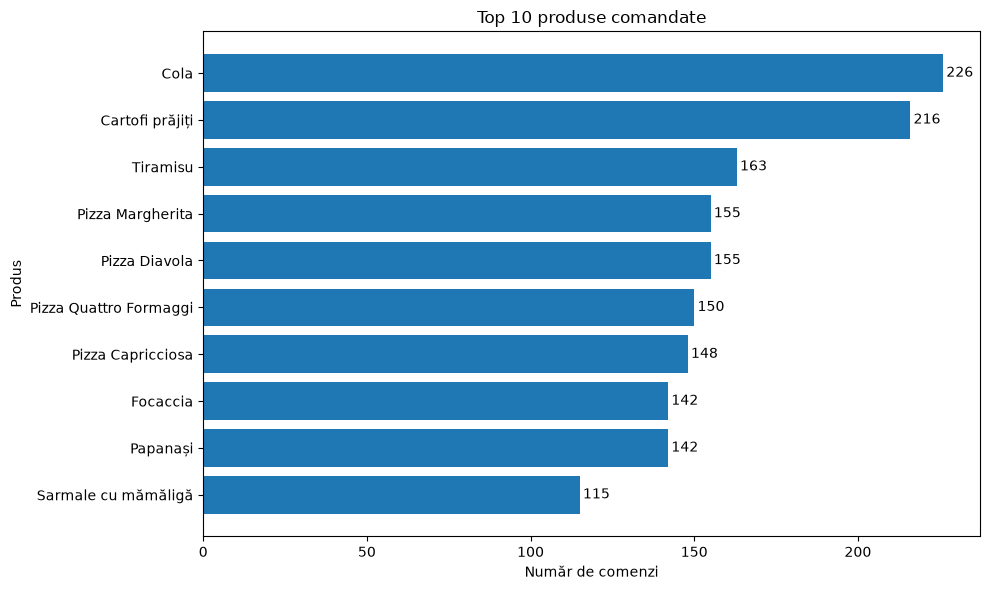

In [38]:
plt.figure(figsize=(10, 6))

valori = top_10_produse.values[::-1]
nume = top_10_produse.index[::-1]

plt.barh(nume, valori)

for i, valoare in enumerate(valori):
    plt.text(valoare + 1, i, str(valoare), va="center")

plt.title("Top 10 produse comandate")
plt.xlabel("Număr de comenzi")
plt.ylabel("Produs")

plt.tight_layout()
plt.show()

#### B2

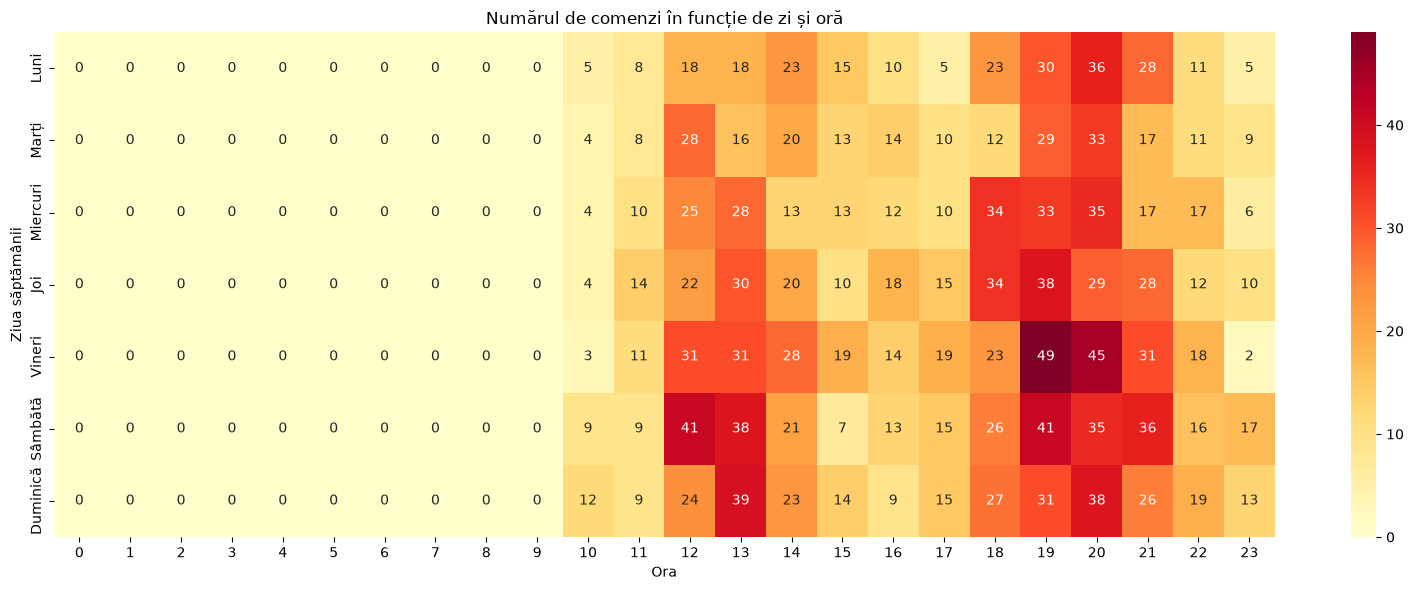

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Dicționar pentru zilele săptămânii
zile_romana = {
    0: "Luni",
    1: "Marți",
    2: "Miercuri",
    3: "Joi",
    4: "Vineri",
    5: "Sâmbătă",
    6: "Duminică"
}

# Crearea pivot table
heatmap_date = pd.pivot_table(
    comenzi,
    index="zi_saptamana",
    columns="ora",
    values="id_comanda",
    aggfunc="count",
    fill_value=0
)

# Transformarea numerelor în denumirile zilelor
heatmap_date.index = heatmap_date.index.map(zile_romana)

# Asigurăm ordinea orelor 0-23
heatmap_date = heatmap_date.reindex(columns=range(24), fill_value=0)

# Heatmap
plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_date,
    annot=True,
    fmt="g",
    cmap="YlOrRd"
)

plt.title("Numărul de comenzi în funcție de zi și oră")
plt.xlabel("Ora")
plt.ylabel("Ziua săptămânii")

plt.tight_layout()
plt.show()